In [1]:
import os
import scanpy as sc
import pandas as pd
from scipy import sparse
import anndata as ad
import sys
import hdf5plugin
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import parameters
import genes
import functions
from scipy.sparse import csr_matrix
import warnings
warnings.filterwarnings("ignore")

# Read data

In [2]:
h509 = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/preprocessed/GSM8058162_KK23-H-509.h5ad")
h512 = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/preprocessed/GSM8058165_KK23-H-512.h5ad")
h225 = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/preprocessed/GSM8058157_KK22-H-225.h5ad")

mouse = sc.read_h5ad("/media/sofia/TOSHIBA EXT/data/mouse/so_12_SP_KO_WT_just_joined_humanized.h5ad")

In [3]:
mouse

AnnData object with n_obs × n_vars = 43045 × 16222
    obs: 'sample_origin', 'condition', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'names', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: 'counts'

In [4]:
h509.X = h509.layers["counts"].copy()
h512.X = h512.layers["counts"].copy()
h225.X = h225.layers["counts"].copy()

In [5]:
h225.obs["sample_origin"] = "h225"
h512.obs["sample_origin"] = "h512"
h509.obs["sample_origin"] = "h509"

In [6]:
mouse.obs["sample_origin"]

12_KO1_SP_AAACCCAAGACGCAGT-1-KO    12_KO1_SP
12_KO1_SP_AAACCCAAGGTCACCC-1-KO    12_KO1_SP
12_KO1_SP_AAACCCAAGGTCTACT-1-KO    12_KO1_SP
12_KO1_SP_AAACCCACAAAGACGC-1-KO    12_KO1_SP
12_KO1_SP_AAACCCACAATTCTTC-1-KO    12_KO1_SP
                                     ...    
12_WT3_SP_TTTGGTTTCTTCCTAA-1-WT    12_WT3_SP
12_WT3_SP_TTTGTTGCACGCGTGT-1-WT    12_WT3_SP
12_WT3_SP_TTTGTTGCAGGCCCTA-1-WT    12_WT3_SP
12_WT3_SP_TTTGTTGCATGTGTCA-1-WT    12_WT3_SP
12_WT3_SP_TTTGTTGGTGTAGGAC-1-WT    12_WT3_SP
Name: sample_origin, Length: 43045, dtype: category
Categories (6, object): ['12_KO1_SP', '12_KO2_SP', '12_KO3_SP', '12_WT1_SP', '12_WT2_SP', '12_WT3_SP']

In [ ]:
small_tumors = sc.concat([h225, h509, h512], join="inner", label="sample.origin", keys=["h225", "h509", "h512"])

In [8]:
small_tumors.obs

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,leiden,S_score,G2M_score,phase,sample_origin,sample.origin
AAACAAGCATTCGGTTACTACTCA-1,1395,1721.0,15.0,0.871586,0.0,0.0,1,0.659020,-0.008597,S,h225,h225
AAACCAGGTTGCATCGACTACTCA-1,1646,2185.0,11.0,0.503432,0.0,0.0,1,-0.026759,-0.098891,G1,h225,h225
AAACGGGCAATAACCGACTACTCA-1,924,1090.0,0.0,0.000000,0.0,0.0,10,-0.205959,-0.104372,G1,h225,h225
AAACTGGGTGCACAAAACTACTCA-1,2196,3515.0,1.0,0.028450,0.0,0.0,7,-0.216795,-0.222631,G1,h225,h225
AAAGATGCAATCGTGAACTACTCA-1,746,835.0,0.0,0.000000,0.0,0.0,3,-0.191717,-0.191717,G1,h225,h225
...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGCCCGTGCCCGATATGTTGAC-1,457,514.0,13.0,2.529183,0.0,0.0,3,-0.050256,-0.011100,G1,h512,h512
TTTGCGCAGGGTGGGAATGTTGAC-1,1472,1822.0,5.0,0.274424,0.0,0.0,1,-0.120025,-0.168452,G1,h512,h512
TTTGCTGAGAGGTTTAATGTTGAC-1,286,306.0,2.0,0.653595,0.0,0.0,0,-0.062895,0.139720,G2M,h512,h512
TTTGCTGAGGGCACTAATGTTGAC-1,295,335.0,15.0,4.477612,0.0,0.0,2,-0.089905,-0.024363,G1,h512,h512


In [9]:
small_tumors_mouse = sc.concat([small_tumors, mouse], join="inner", label="species", keys=["human", "mouse"])

In [10]:
small_tumors_mouse = functions.preprocess_adata(small_tumors_mouse)

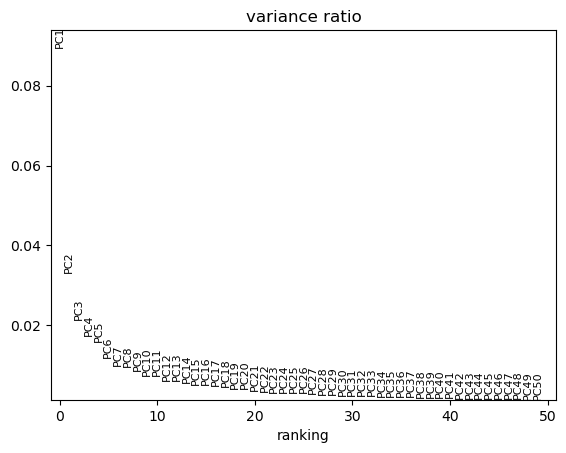

In [11]:
sc.pp.pca(small_tumors_mouse, use_highly_variable=True,  n_comps=50, layer="scale.data") #compute PCA using the scaled data in the "scale.data" layer, and only using the highly variable genes identified earlier

sc.pl.pca_variance_ratio(small_tumors_mouse, n_pcs=50, log=False, show=False) #plot the variance explained by each of the first 50 PCs, to help determine how many PCs to use for downstream analyses

In [12]:
sc.external.pp.harmony_integrate(small_tumors_mouse, key="sample_origin")

2026-03-03 18:28:10,914 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-03-03 18:28:26,524 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-03-03 18:28:26,924 - harmonypy - INFO - Iteration 1 of 10
2026-03-03 18:28:56,043 - harmonypy - INFO - Iteration 2 of 10
2026-03-03 18:29:24,625 - harmonypy - INFO - Iteration 3 of 10
2026-03-03 18:29:53,136 - harmonypy - INFO - Converged after 3 iterations


In [14]:
small_tumors_mouse

AnnData object with n_obs × n_vars = 48571 × 15196
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'sample_origin', 'species'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca', 'X_pca_harmony'
    varm: 'PCs'
    layers: 'counts', 'scale.data'

In [15]:
pc_parameters = parameters.pc_parameters

sc.pp.neighbors(
                small_tumors_mouse,
                n_neighbors=pc_parameters["n_neighbors"],
                n_pcs=pc_parameters["n_pcs"],
                use_rep="X_pca_harmony"
            ) #compute the neighborhood graph of cells using the specified number of neighbors and PCs, which will be used for UMAP and Leiden clustering

            # UMAP
sc.tl.umap(
                small_tumors_mouse
            )

            # Leiden
sc.tl.leiden(
                small_tumors_mouse,
                resolution=pc_parameters["leiden_resolution"]
            )



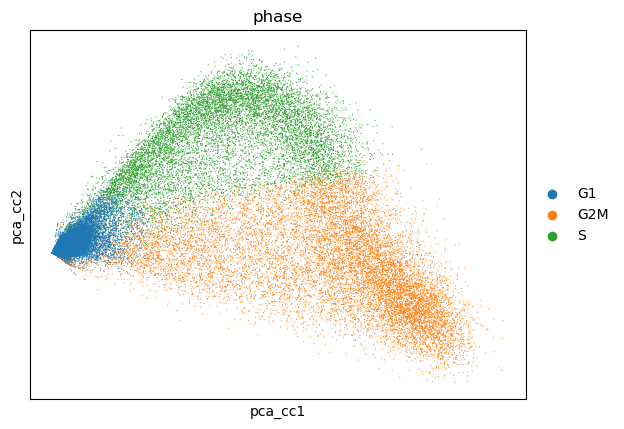

In [16]:
s_genes = [x for x in genes.s_genes if x in small_tumors_mouse.var_names]

g2m_genes = [x for x in genes.g2m_genes if x in small_tumors_mouse.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

sc.tl.score_genes_cell_cycle(small_tumors_mouse, s_genes=s_genes, g2m_genes=g2m_genes)

datacc_genes = small_tumors_mouse[:, cell_cycle_genes].copy()
sc.tl.pca(datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(datacc_genes, color="phase", basis="pca_cc")

sc.tl.rank_genes_groups(small_tumors_mouse, groupby="leiden",  method="wilcoxon", use_raw=False)

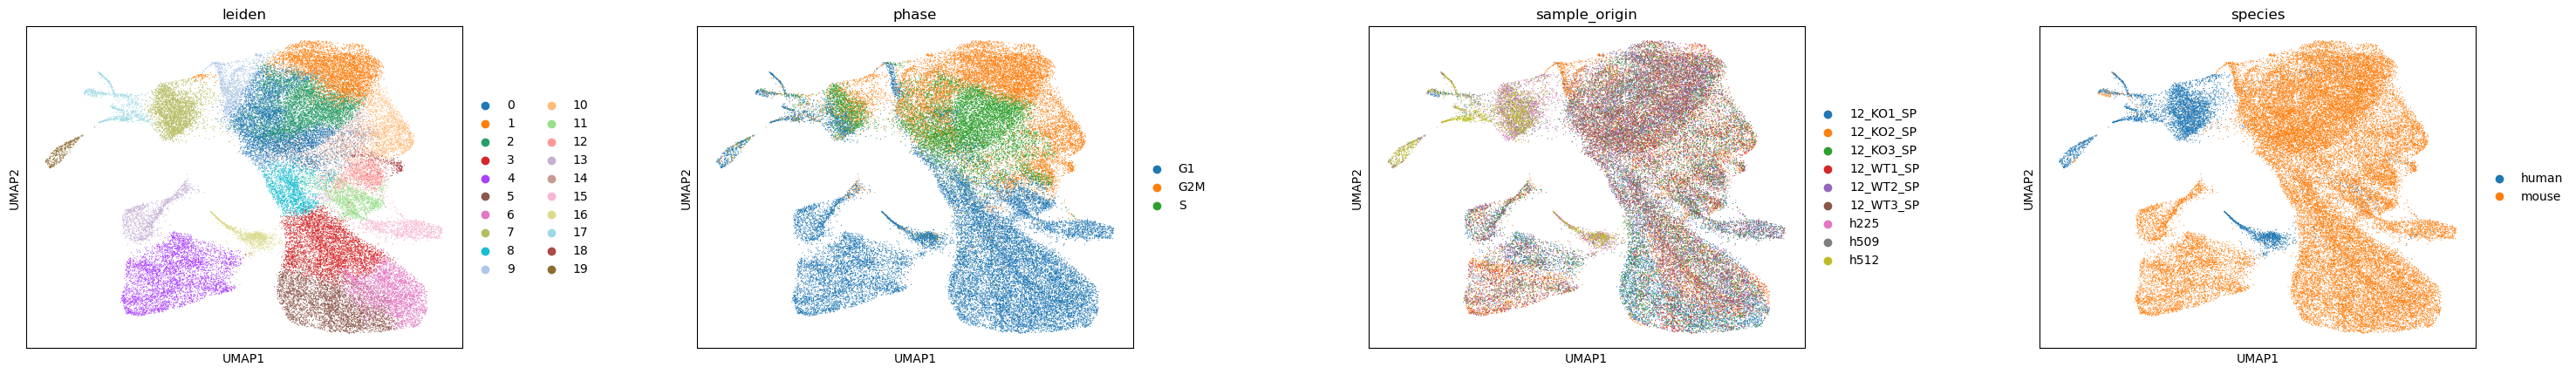

In [17]:
sc.pl.embedding(small_tumors_mouse, basis="umap", color=["leiden", "phase", "sample_origin", "species"], wspace=0.4)